<a href="https://colab.research.google.com/github/Jeswinkuttiyani/Casestudy/blob/main/SupervisedLearningCaseStudy_Jeswin_Jose.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Churn Prediction – Telecommunications Case Study

## Introduction and Objective
The objective is to build a classification model that identifies telecommunications customers who are likely to leave the company (churn), so that the business can target them with suitable retention offers. The notebook follows the case-study requirements: exploratory data analysis, data preprocessing, feature engineering and selection, development and comparison of at least three models, hyperparameter tuning, final testing, and business recommendations.

**Target variable:** `Churn` (`Yes` = 1, `No` = 0). `customerID` is an identifier and is excluded from model predictors.

> The EDA/preprocessing cells below document the data and demonstrate cleaning/encoding. For the final model evaluation, the additional leakage-safe workflow at the end reloads the original CSV files and fits imputers, encoders and scalers only on training folds. Use that final workflow's results as the authoritative model results.

In [137]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

In [138]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **Exploratory Data Analysis (EDA):**

In [139]:
#understanding the data
df =pd.read_csv("/content/drive/MyDrive/Data Science/Data Set/Training_data.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,9509-MPYOD,Female,0,No,No,35,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.75,700.45,No
1,7746-AWNQW,Female,0,No,No,28,No,No phone service,DSL,No,...,Yes,Yes,No,No,Month-to-month,Yes,Mailed check,35.75,961.4,No
2,2208-UGTGR,Male,0,No,No,56,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,No,Electronic check,98.60,5581.05,No
3,4884-LEVMQ,Male,0,Yes,No,39,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),20.45,790,No
4,6682-VCIXC,Female,0,Yes,Yes,43,No,No phone service,DSL,NaN,...,No,Yes,Yes,No,One year,Yes,Bank transfer (automatic),51.25,2151.6,No


In [140]:
# First five records
display(df.head())

# Number of rows and columns
print("Dataset Shape:", df.shape)

# Column names
print(df.columns.tolist())

# Data types and non-null counts
df.info()

# Statistical summary
display(df.describe(include="all"))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,9509-MPYOD,Female,0,No,No,35,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.75,700.45,No
1,7746-AWNQW,Female,0,No,No,28,No,No phone service,DSL,No,...,Yes,Yes,No,No,Month-to-month,Yes,Mailed check,35.75,961.4,No
2,2208-UGTGR,Male,0,No,No,56,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,No,Electronic check,98.60,5581.05,No
3,4884-LEVMQ,Male,0,Yes,No,39,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),20.45,790,No
4,6682-VCIXC,Female,0,Yes,Yes,43,No,No phone service,DSL,NaN,...,No,Yes,Yes,No,One year,Yes,Bank transfer (automatic),51.25,2151.6,No


Dataset Shape: (5634, 21)
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   object 
 1   gender            5465 non-null   object 
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   object 
 4   Dependents        5634 non-null   object 
 5   tenure            5634 non-null   int64  
 6   PhoneService      5634 non-null   object 
 7   MultipleLines     5634 non-null   object 
 8   InternetService   5634 non-null   object 
 9   OnlineSecurity    546

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,5634,5465,5634.000000,5634,5634,5634.000000,5634,5634,5634,5465,...,5634,5634,5634,5634,5634,5634,5634,5240.000000,5353,5634
unique,5634,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,5040,2
top,9509-MPYOD,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,2744,NaN,2890,3960,NaN,5081,2701,2486,2720,...,2485,2782,2244,2232,3094,3350,1892,NaN,9,4130
mean,NaN,NaN,0.159744,NaN,NaN,32.606851,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65.102052,NaN,NaN
std,NaN,NaN,0.366401,NaN,NaN,24.614976,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.056443,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36.800000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.650000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,56.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,90.050000,NaN,NaN


In [141]:
#identify the missing values
# Missing values in each column
df.isna().sum()

,0
customerID,0
gender,169
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,169


In [142]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


Churn
No     4130
Yes    1504
Name: count, dtype: int64


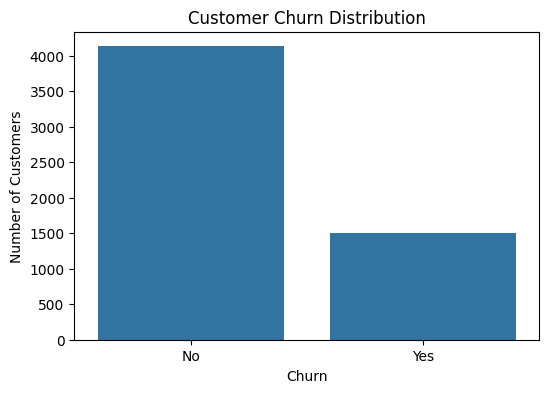

In [143]:
print(df["Churn"].value_counts())

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [144]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

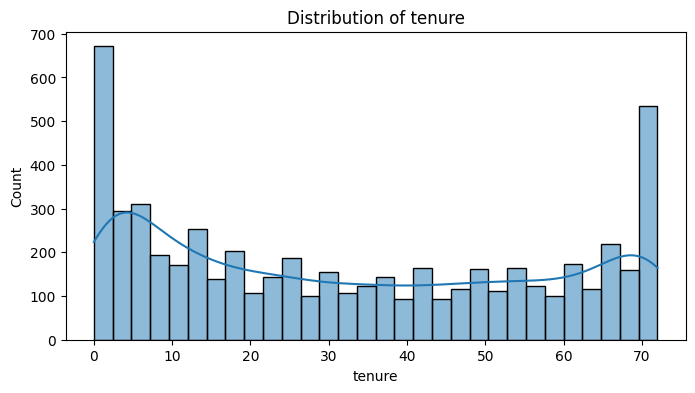

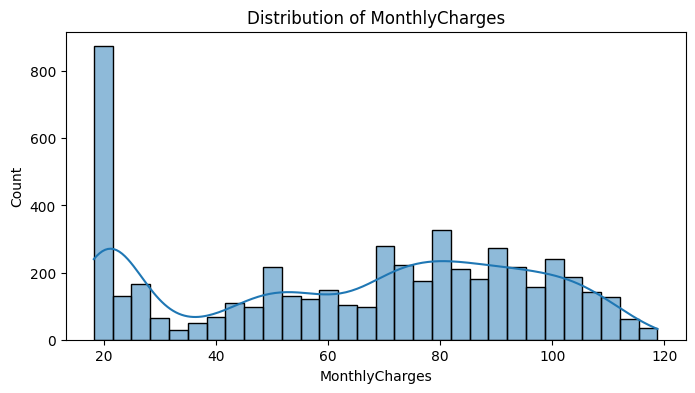

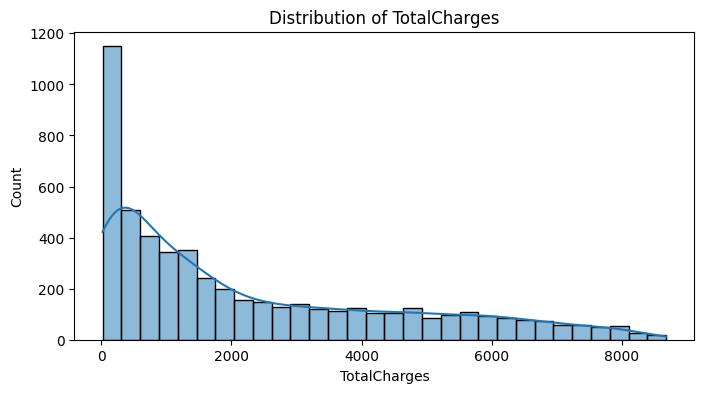

In [145]:
numerical_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for col in numerical_cols:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")
    plt.show()

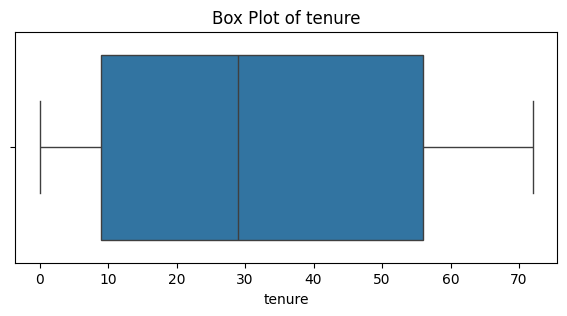

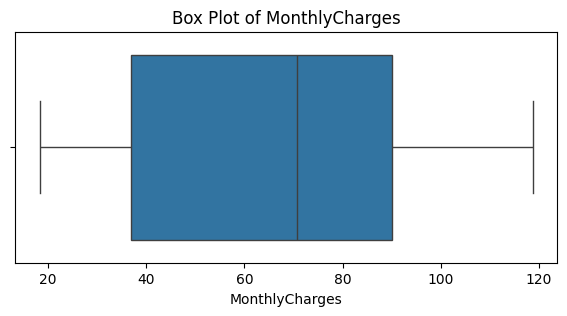

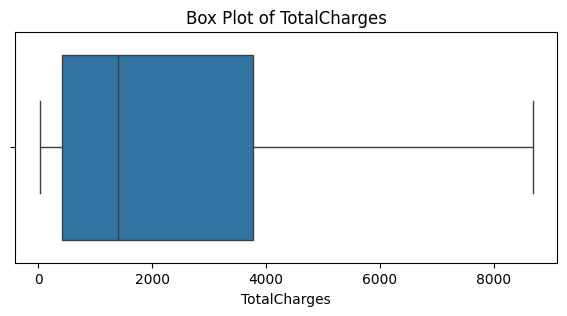

In [146]:
#outlier detection
for col in numerical_cols:

    plt.figure(figsize=(7, 3))

    sns.boxplot(x=df[col])

    plt.title(f"Box Plot of {col}")
    plt.show()

In [147]:
for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]

    print(col, "Outliers:", len(outliers))

tenure Outliers: 0
MonthlyCharges Outliers: 0
TotalCharges Outliers: 0


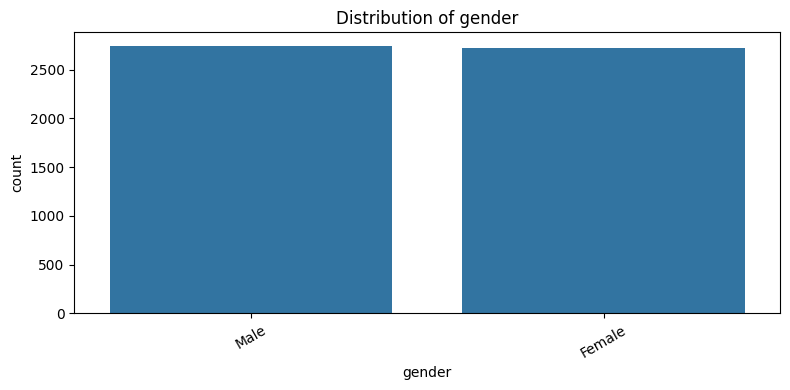

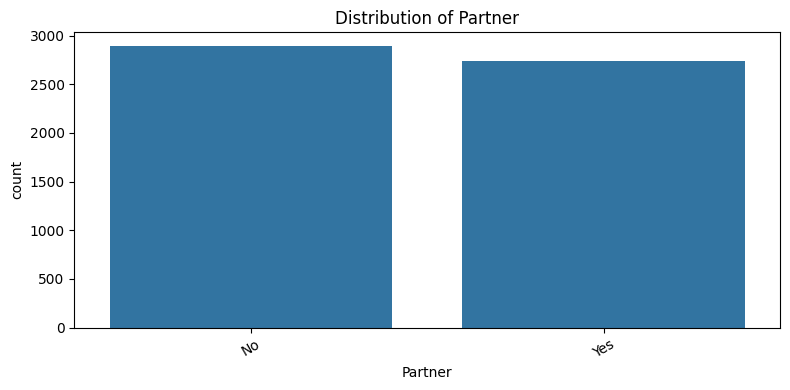

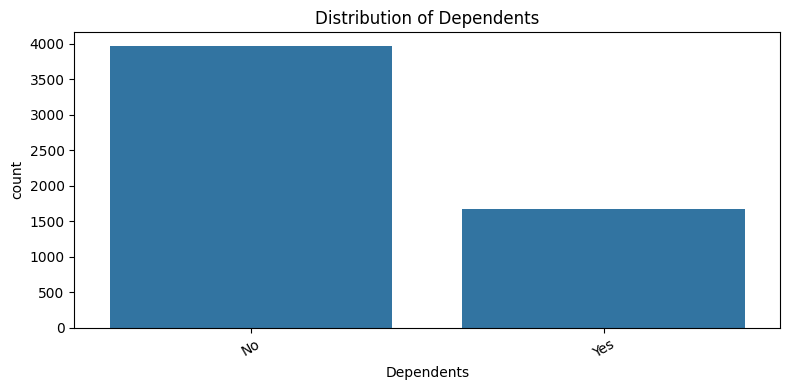

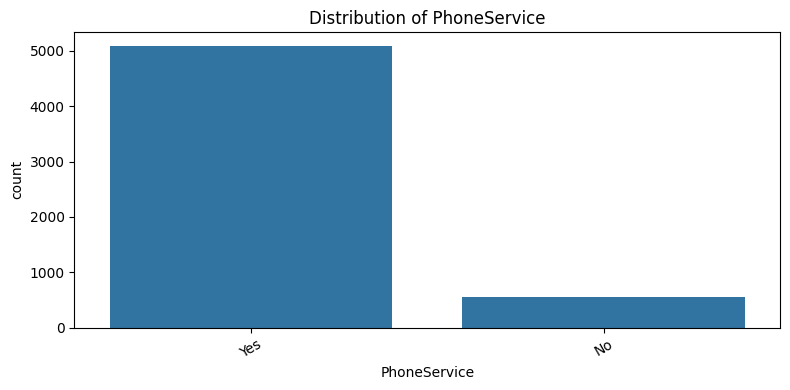

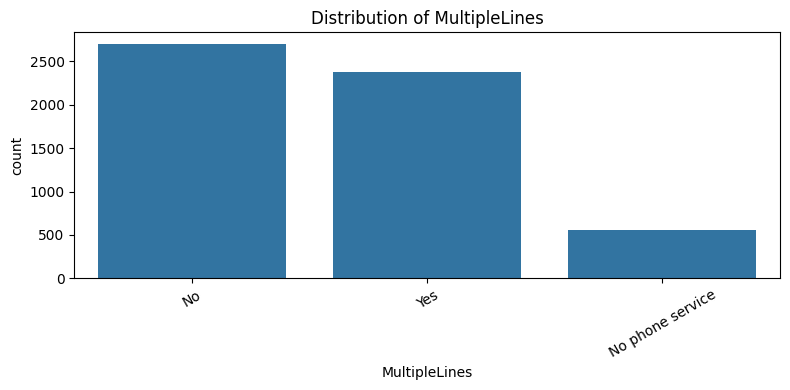

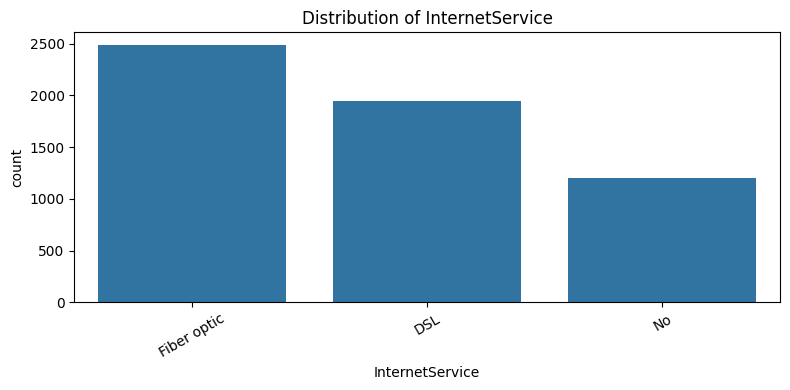

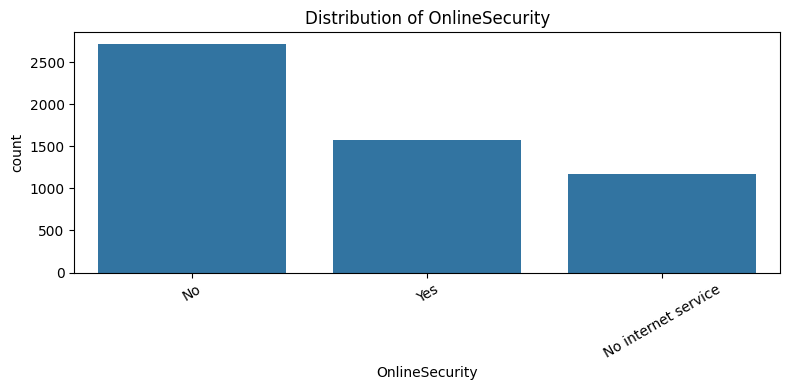

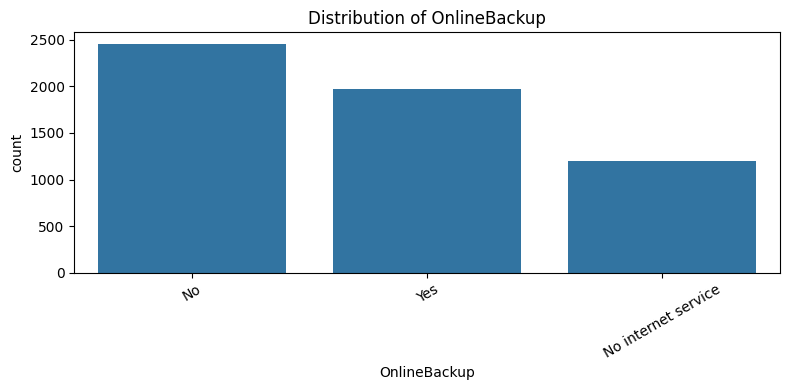

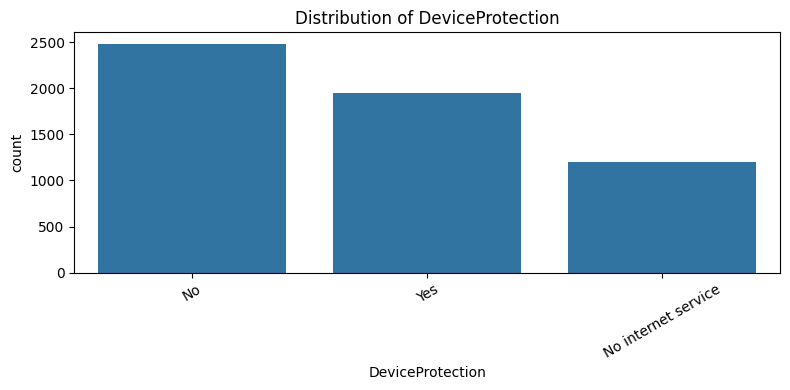

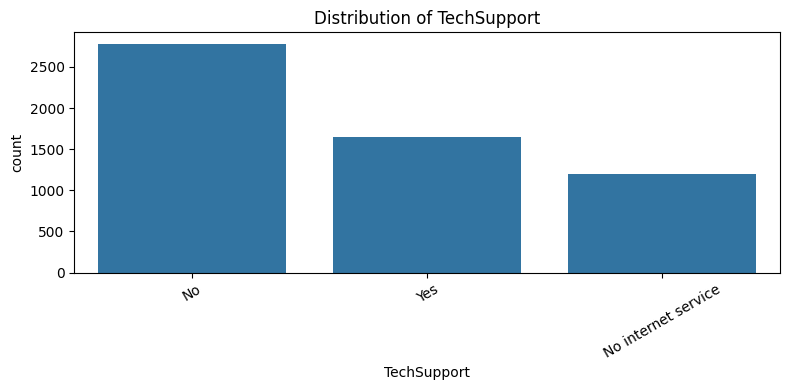

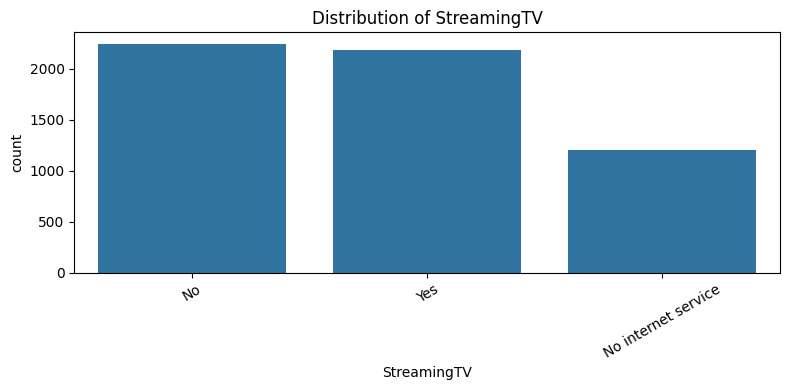

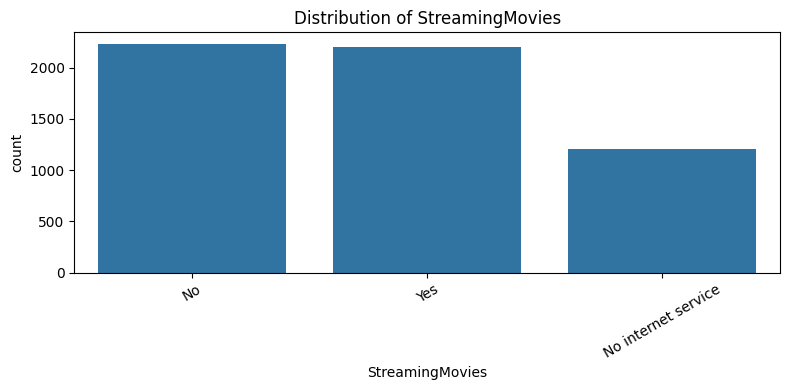

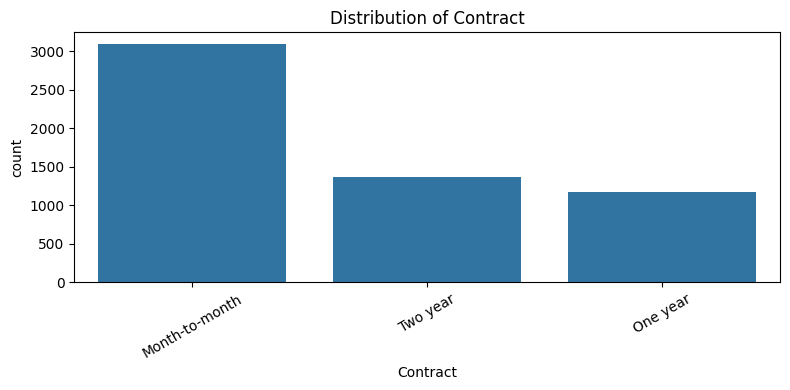

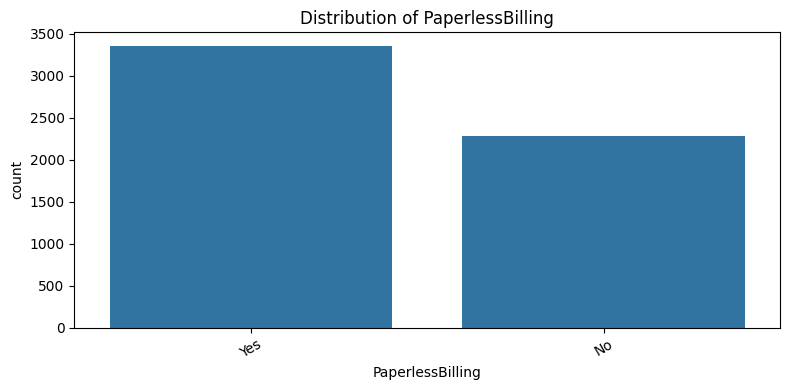

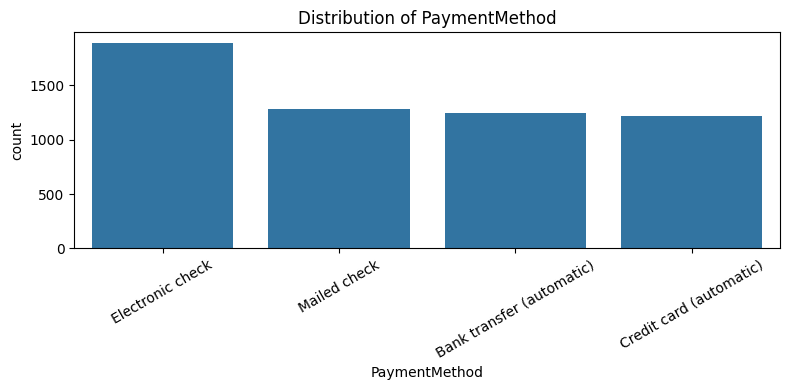

In [148]:
categorical_cols = df.select_dtypes(
    include="object"
).columns.drop(["customerID", "TotalCharges", "Churn"], errors="ignore")

for col in categorical_cols:

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index
    )

    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

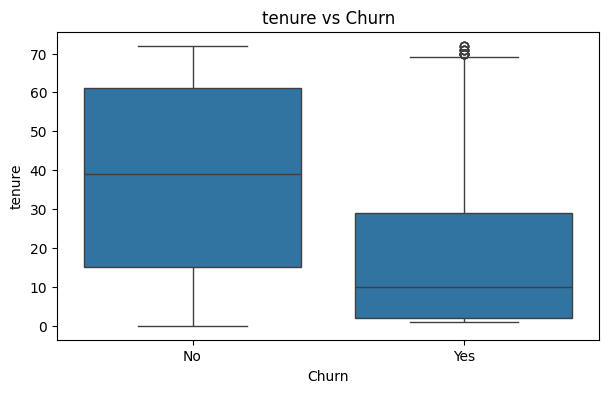

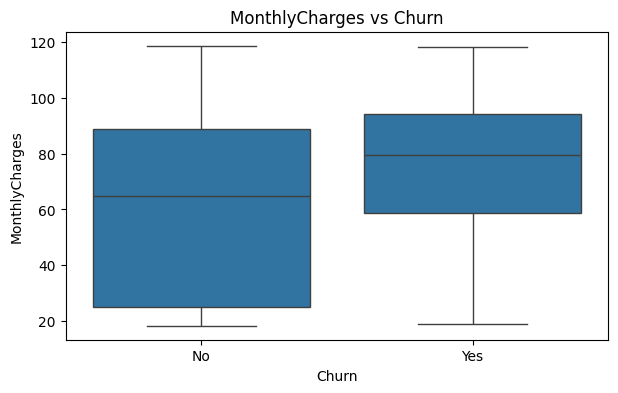

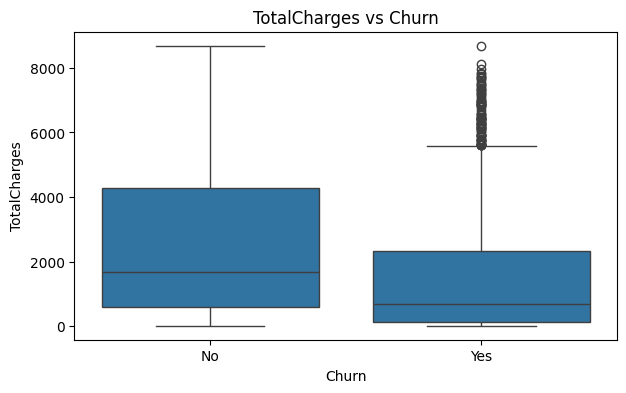

In [149]:
for col in numerical_cols:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="Churn",
        y=col
    )

    plt.title(f"{col} vs Churn")
    plt.show()

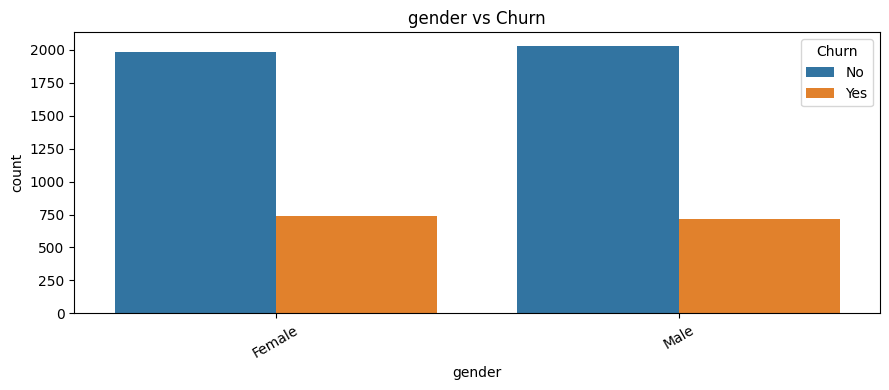

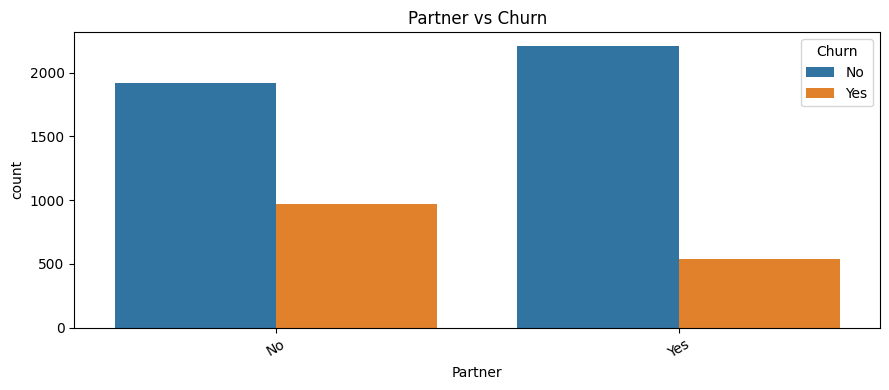

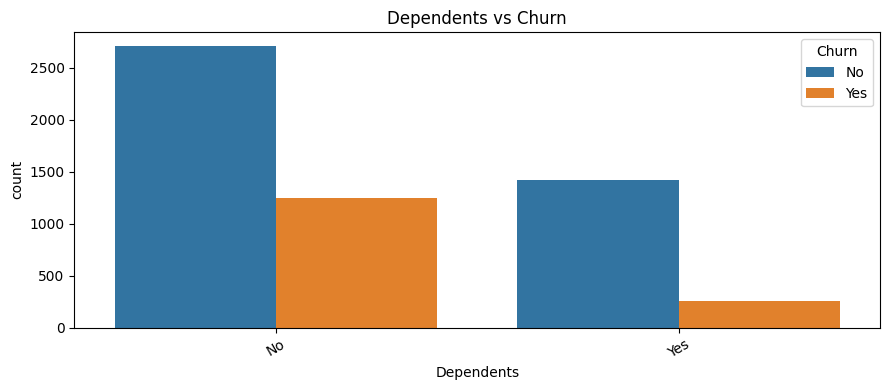

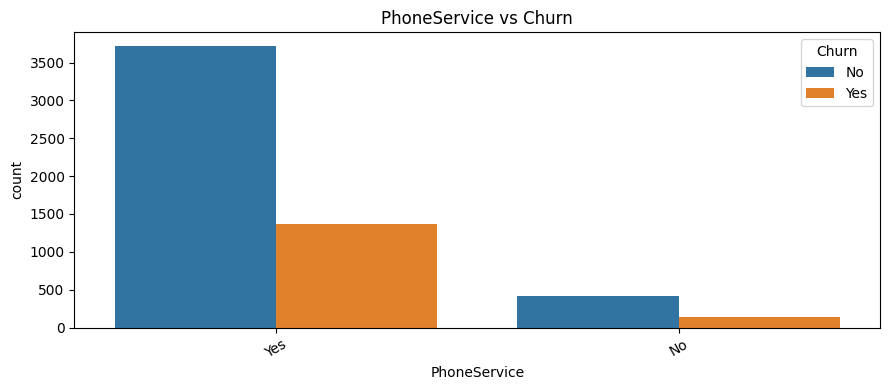

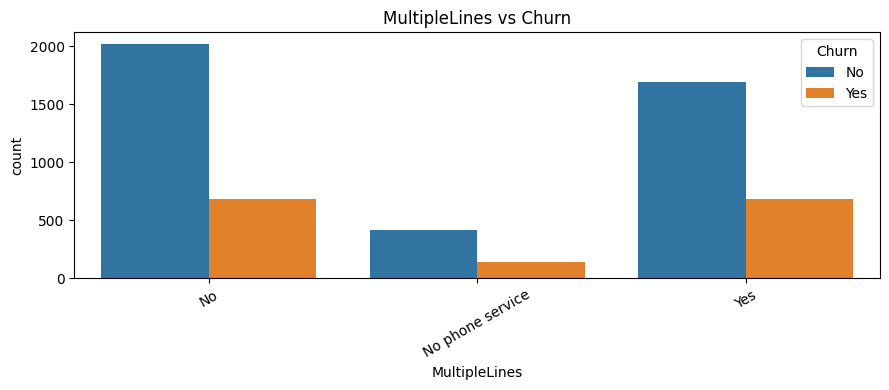

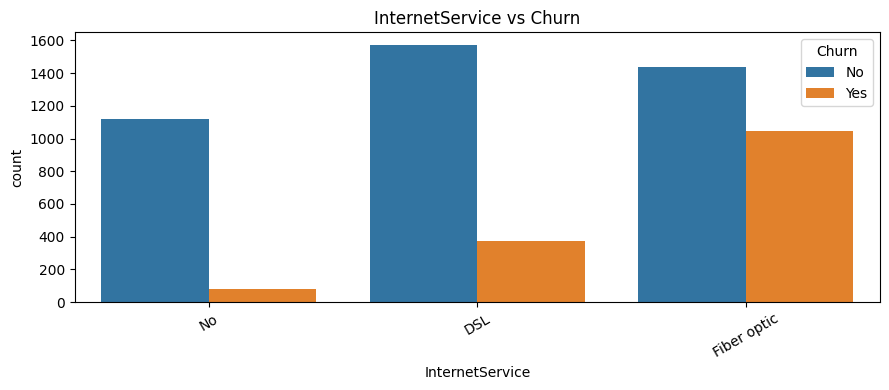

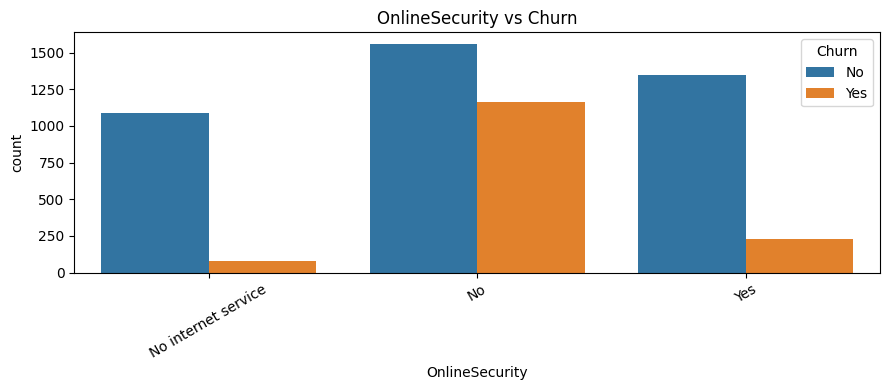

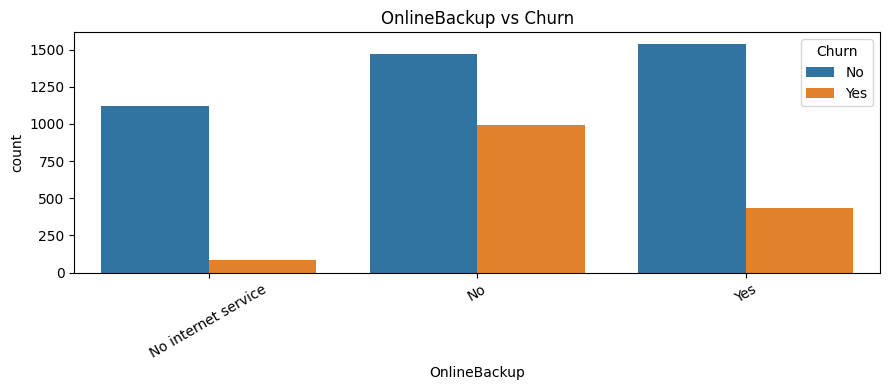

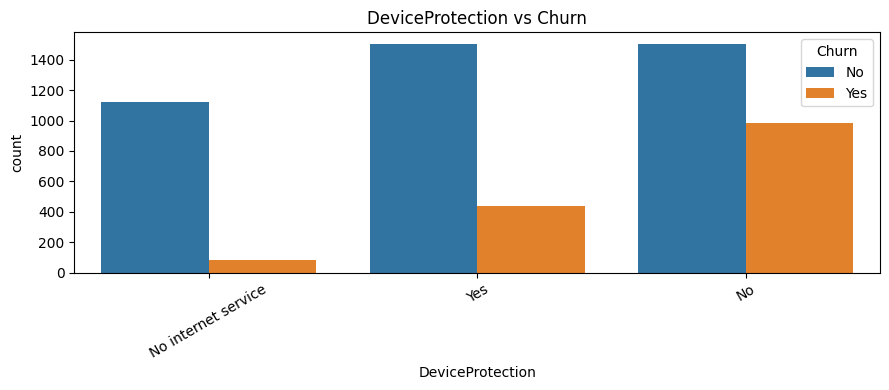

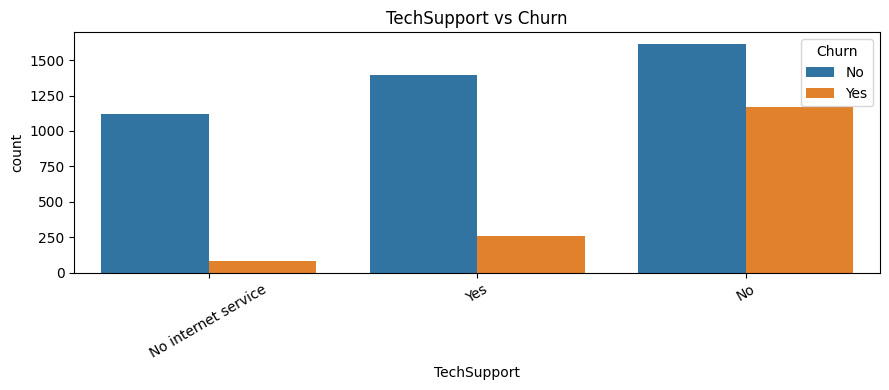

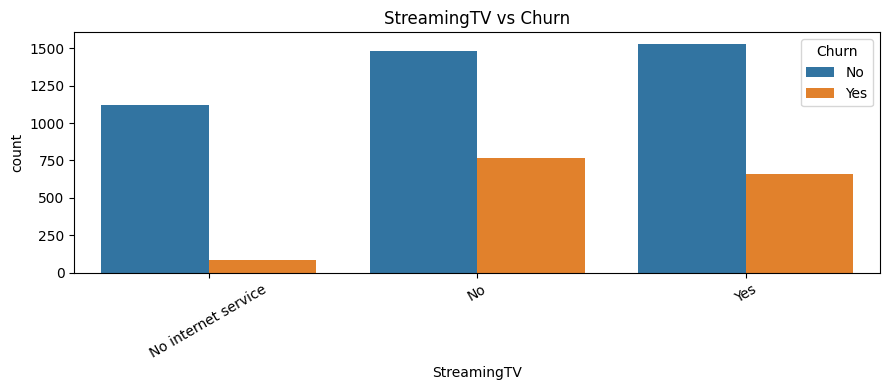

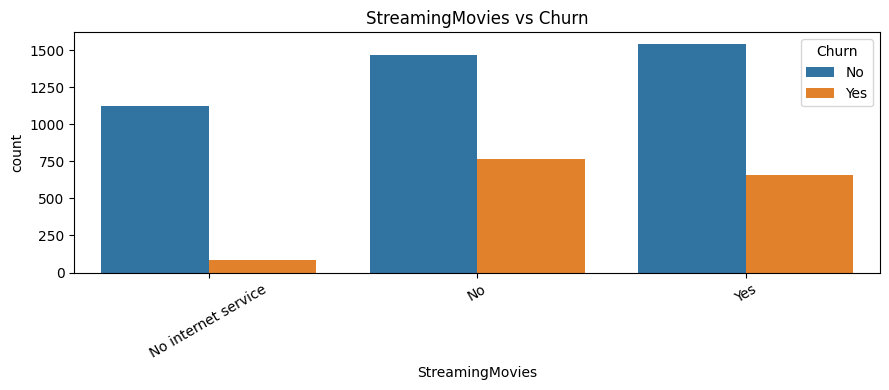

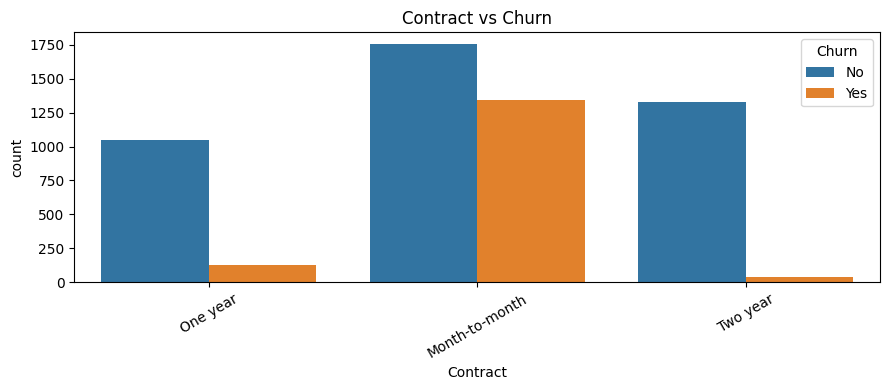

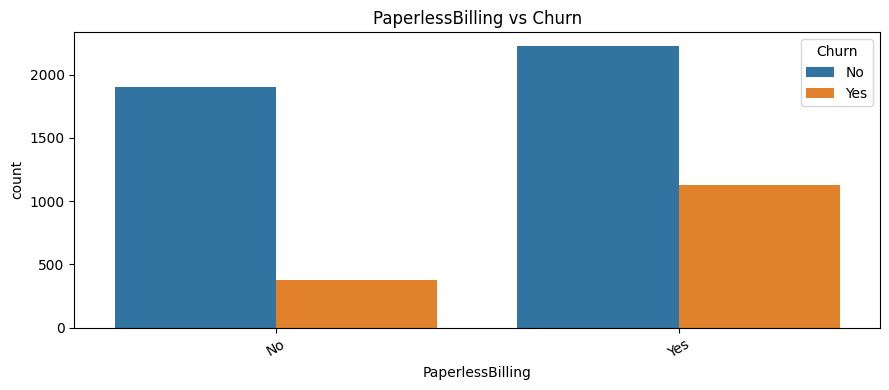

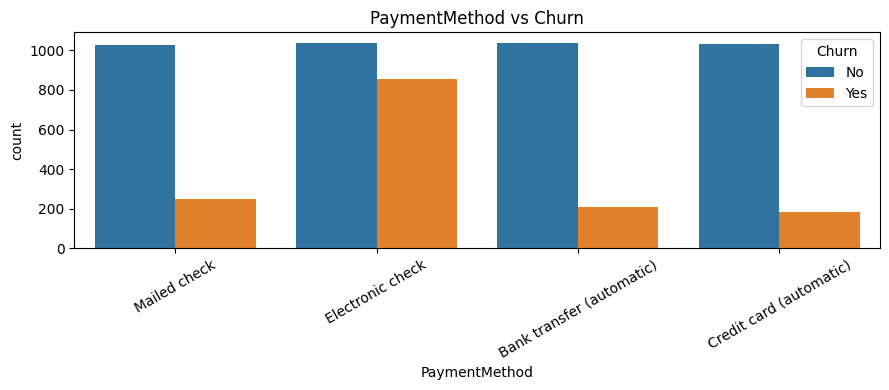

In [150]:
for col in categorical_cols:

    plt.figure(figsize=(9, 4))

    sns.countplot(
        data=df,
        x=col,
        hue="Churn"
    )

    plt.title(f"{col} vs Churn")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

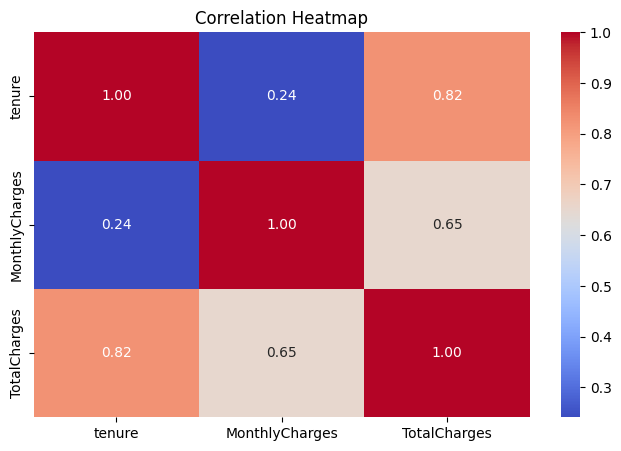

In [151]:
# Numerical correlation
correlation = df[numerical_cols].corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

# **Data Preprocessing**

**Handle missing values**

In [152]:
# Check missing values
df.isnull().sum()

,0
customerID,0
gender,169
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,169


In [153]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

In [154]:
#handling Total charrges  to 0 where tenure == 0
df.loc[
    (df["tenure"] == 0) &
    (df["TotalCharges"].isnull()),
    "TotalCharges"
] = 0

In [155]:
# missing value is filled with mode and  median
df["MonthlyCharges"] = df["MonthlyCharges"].fillna(
    df["MonthlyCharges"].median()
)

df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)


df["gender"] = df["gender"].fillna(
    df["gender"].mode()[0]
)


# OnlineSecurity: preserve missingness as a separate category
df["OnlineSecurity"] = df["OnlineSecurity"].fillna(
    "Missing"
)

In [156]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


**Encoding categorical variables**

Machine learning algorithms generally require numerical input. However, your dataset contains categorical values such as:
*   Male, Female,
*   Yes, No
Encoding converts these categorical values into numerical representations.



In [157]:
#Identify categorical columns

categorical_cols = df.select_dtypes(
    include="object"
).columns.tolist()

categorical_cols.remove("customerID")
categorical_cols.remove("Churn")

print(categorical_cols)

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [158]:
df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

df_encoded.head()

,customerID,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,9509-MPYOD,0,35,20.75,700.45,No,0,0,0,1,...,1,0,1,0,1,0,0,0,0,1
1,7746-AWNQW,0,28,35.75,961.40,No,0,0,0,0,...,0,0,0,0,0,0,1,0,0,1
2,2208-UGTGR,0,56,98.60,5581.05,No,1,0,0,1,...,0,1,0,1,0,0,0,0,1,0
3,4884-LEVMQ,0,39,20.45,790.00,No,1,1,0,1,...,1,0,1,0,0,1,1,0,0,0
4,6682-VCIXC,0,43,51.25,2151.60,No,0,1,1,0,...,0,1,0,0,1,0,1,0,0,0


In [159]:
print("Original shape:", df.shape)
print("Encoded shape:", df_encoded.shape)

df_encoded.select_dtypes(
    include="object"
).columns


Original shape: (5634, 21)
Encoded shape: (5634, 33)


Index(['customerID', 'Churn'], dtype='object')

**Normalization and scaling of numerical features**

In [160]:
numerical_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

df[numerical_cols].describe()

,tenure,MonthlyCharges,TotalCharges
count,5634.000000,5634.000000,5634.000000
mean,32.606851,65.490034,2235.780573
std,24.614976,29.020760,2217.933997
min,0.000000,18.250000,0.000000
25%,9.000000,44.000000,439.862500
50%,29.000000,70.650000,1391.650000
75%,56.000000,89.100000,3590.537500
max,72.000000,118.750000,8684.800000


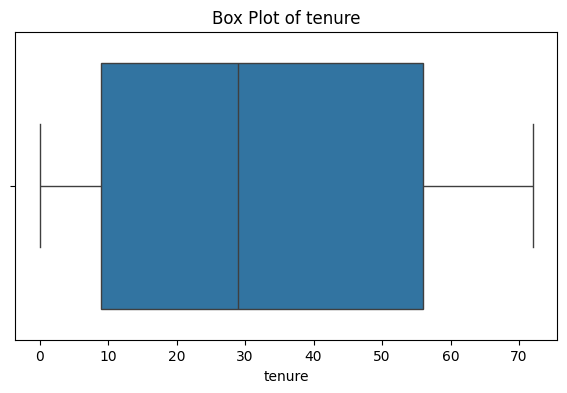

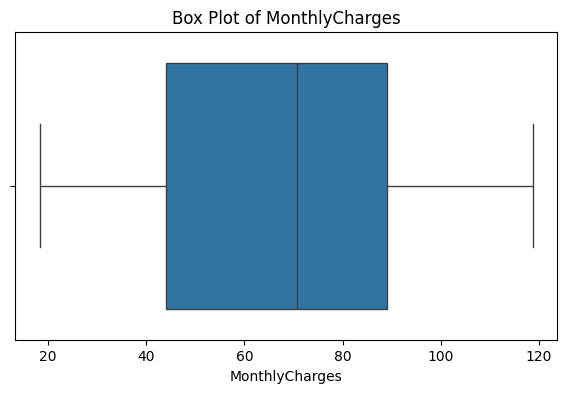

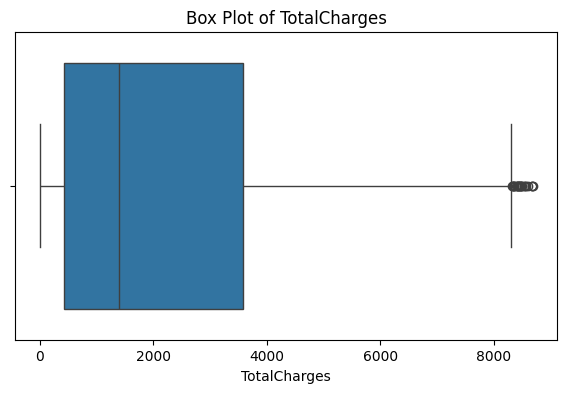

In [161]:
for col in numerical_cols:

    plt.figure(figsize=(7, 4))

    sns.boxplot(x=df[col])

    plt.title(f"Box Plot of {col}")
    plt.xlabel(col)

    plt.show()

In [162]:
#outlier detection
for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(f"\nFeature: {col}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Number of Outliers:", len(outliers))


Feature: tenure
Q1: 9.0
Q3: 56.0
IQR: 47.0
Lower Limit: -61.5
Upper Limit: 126.5
Number of Outliers: 0

Feature: MonthlyCharges
Q1: 44.0
Q3: 89.1
IQR: 45.099999999999994
Lower Limit: -23.64999999999999
Upper Limit: 156.75
Number of Outliers: 0

Feature: TotalCharges
Q1: 439.8625
Q3: 3590.5375
IQR: 3150.6749999999997
Lower Limit: -4286.15
Upper Limit: 8316.55
Number of Outliers: 23


In [163]:
Q1 = df["TotalCharges"].quantile(0.25)
Q3 = df["TotalCharges"].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

outliers = df[df["TotalCharges"] > upper_limit]

display(
    outliers[
        ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ].sort_values("TotalCharges", ascending=False)
)

,tenure,MonthlyCharges,TotalCharges,Churn
2085,72,117.80,8684.80,Yes
4496,72,118.75,8672.45,No
1959,72,117.50,8670.10,No
2843,72,116.95,8594.40,No
4567,71,116.25,8564.75,No
4469,72,116.40,8543.25,No
4985,72,70.65,8529.50,No
111,72,114.90,8496.70,No
4284,71,118.65,8477.60,No
269,72,115.80,8476.50,No


**Outlier assessment:** The IQR analysis in the preprocessing section identified 23 potential outliers in `TotalCharges`. These observations were reviewed and retained because they were plausible high-value customers with long tenure and higher monthly charges. IQR flags are statistical indicators, not proof of data errors.

# **Feature Engineering**

Feature Engineering is the process of creating new features from existing features to help machine learning models identify useful patterns.

In [164]:
#Tenure and Contract Interaction
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "New",
        "Short_Term",
        "Medium_Term",
        "Long_Term"
    ]
)
df["Tenure_Contract"] = (
    df["TenureGroup"].astype(str)
    + "_"
    + df["Contract"].astype(str)
)
display(
    df[
        ["tenure", "Contract",
         "TenureGroup", "Tenure_Contract"]
    ].head(10)
)

,tenure,Contract,TenureGroup,Tenure_Contract
0,35,One year,Medium_Term,Medium_Term_One year
1,28,Month-to-month,Medium_Term,Medium_Term_Month-to-month
2,56,Month-to-month,Long_Term,Long_Term_Month-to-month
3,39,Two year,Medium_Term,Medium_Term_Two year
4,43,One year,Medium_Term,Medium_Term_One year
5,39,Month-to-month,Medium_Term,Medium_Term_Month-to-month
6,2,One year,New,New_One year
7,18,One year,Short_Term,Short_Term_One year
8,63,Month-to-month,Long_Term,Long_Term_Month-to-month
9,40,Month-to-month,Medium_Term,Medium_Term_Month-to-month


In [165]:
# Create Customer Lifetime Value feature

df["CLV"] = (
    df["tenure"] * df["MonthlyCharges"]
)

df[["tenure", "MonthlyCharges", "CLV"]].head()

,tenure,MonthlyCharges,CLV
0,35,20.75,726.25
1,28,35.75,1001.00
2,56,98.60,5521.60
3,39,20.45,797.55
4,43,51.25,2203.75


**Feature selection**

In [166]:
# Separate features and target
# Input features
X = df.drop(columns=["customerID", "Churn"])

# Target variable
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Features:", X.shape)
print("Target:", y.shape)

Features: (5634, 22)
Target: (5634,)


In [167]:
#Identify numerical and categorical columns
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

X = df.drop(columns=["customerID", "Churn"])

In [168]:
#Identify the columns:
numerical_cols = X.select_dtypes(
    include="number"
).columns.tolist()

categorical_cols = X.select_dtypes(
    include="object"
).columns.tolist()

print("Numerical:", numerical_cols)
print("Categorical:", categorical_cols)

Numerical: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'CLV']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Tenure_Contract']


In [169]:
#Split the dataset
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [170]:
# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

In [171]:
#Train Random Forest
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges', 'CLV']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod',
                                                   'Tenure_Contract'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, random_state=42))])

In [172]:
# Get feature names after encoding
feature_names = rf_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get importance scores
importance = rf_pipeline.named_steps[
    "model"
].feature_importances_

# Create DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort in descending order
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
3,num__TotalCharges,0.098091
4,num__CLV,0.095974
1,num__tenure,0.095371
2,num__MonthlyCharges,0.090940
38,cat__Contract_Month-to-month,0.062801
29,cat__TechSupport_No,0.037883
20,cat__OnlineSecurity_No,0.032500
40,cat__Contract_Two year,0.028149
17,cat__InternetService_Fiber optic,0.024920
53,cat__Tenure_Contract_New_Month-to-month,0.024881


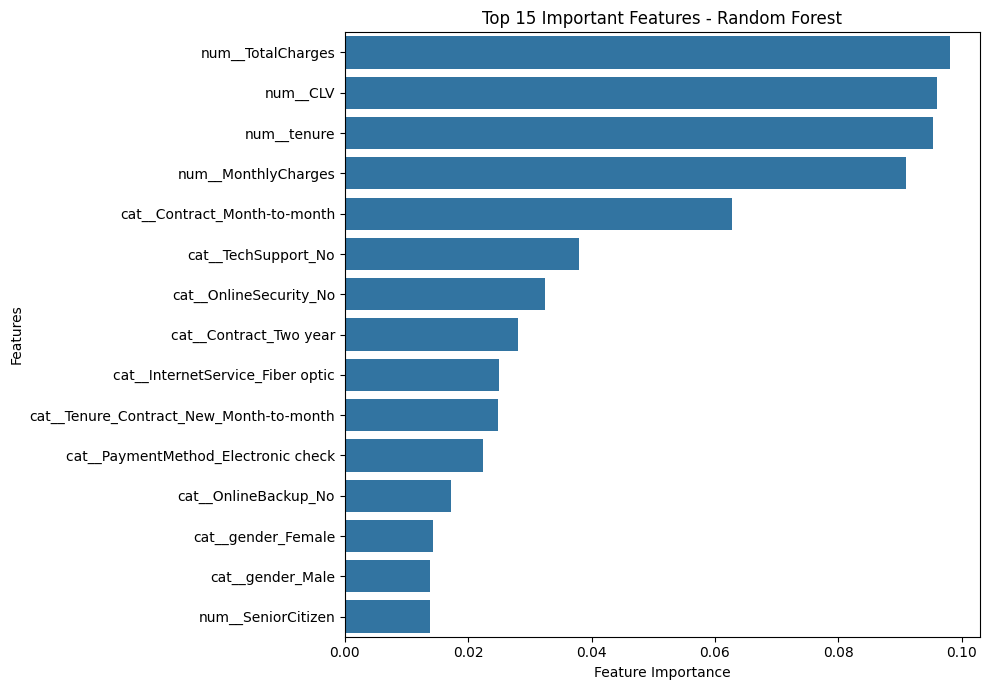

In [173]:
#Plot Top 15 important features
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

# **Model Development**

In [174]:
#Prepare the dataset
# Convert TotalCharges into numeric format
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# Input features
X = df.drop(columns=["customerID", "Churn"])

# Target variable
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5634, 22)
y shape: (5634,)


In [175]:
#Split the dataset
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("Training target:", y_train.shape)
print("Validation target:", y_val.shape)

Training features: (4507, 22)
Validation features: (1127, 22)
Training target: (4507,)
Validation target: (1127,)


In [176]:
#Scaling
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [177]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [178]:
preprocessor = ColumnTransformer([
    ("numerical", numeric_pipeline, numerical_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])


**Logistic Regression**

In [179]:
from sklearn.linear_model import LogisticRegression

In [180]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

In [181]:
logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges', 'CLV']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_u...ignore'))]),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod',
                                                   'Tenure_Contract'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [182]:
y_prob_lr = logistic_model.predict_proba(X_val)[:, 1]

print(y_prob_lr[:10])

[0.02142128 0.40026343 0.02289574 0.649978   0.04017228 0.66177052
 0.08068359 0.88734383 0.0202821  0.13473297]


**Decision Tree Classifier**

In [183]:
from sklearn.tree import DecisionTreeClassifier

In [184]:
numeric_pipeline_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_tree = ColumnTransformer([
    ("numerical", numeric_pipeline_tree, numerical_cols),
    ("categorical", categorical_pipeline_tree, categorical_cols)
])

In [185]:
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])
decision_tree_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges', 'CLV']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod',
                                                   'Tenure_Contract'])])),
                ('classifier',
                 DecisionTreeClassifier(class_weight='balanced',
                                        random_state=42))])

In [186]:
y_prob_dt = decision_tree_model.predict_proba(X_val)[:, 1]

print(y_prob_dt[:10])

[0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]


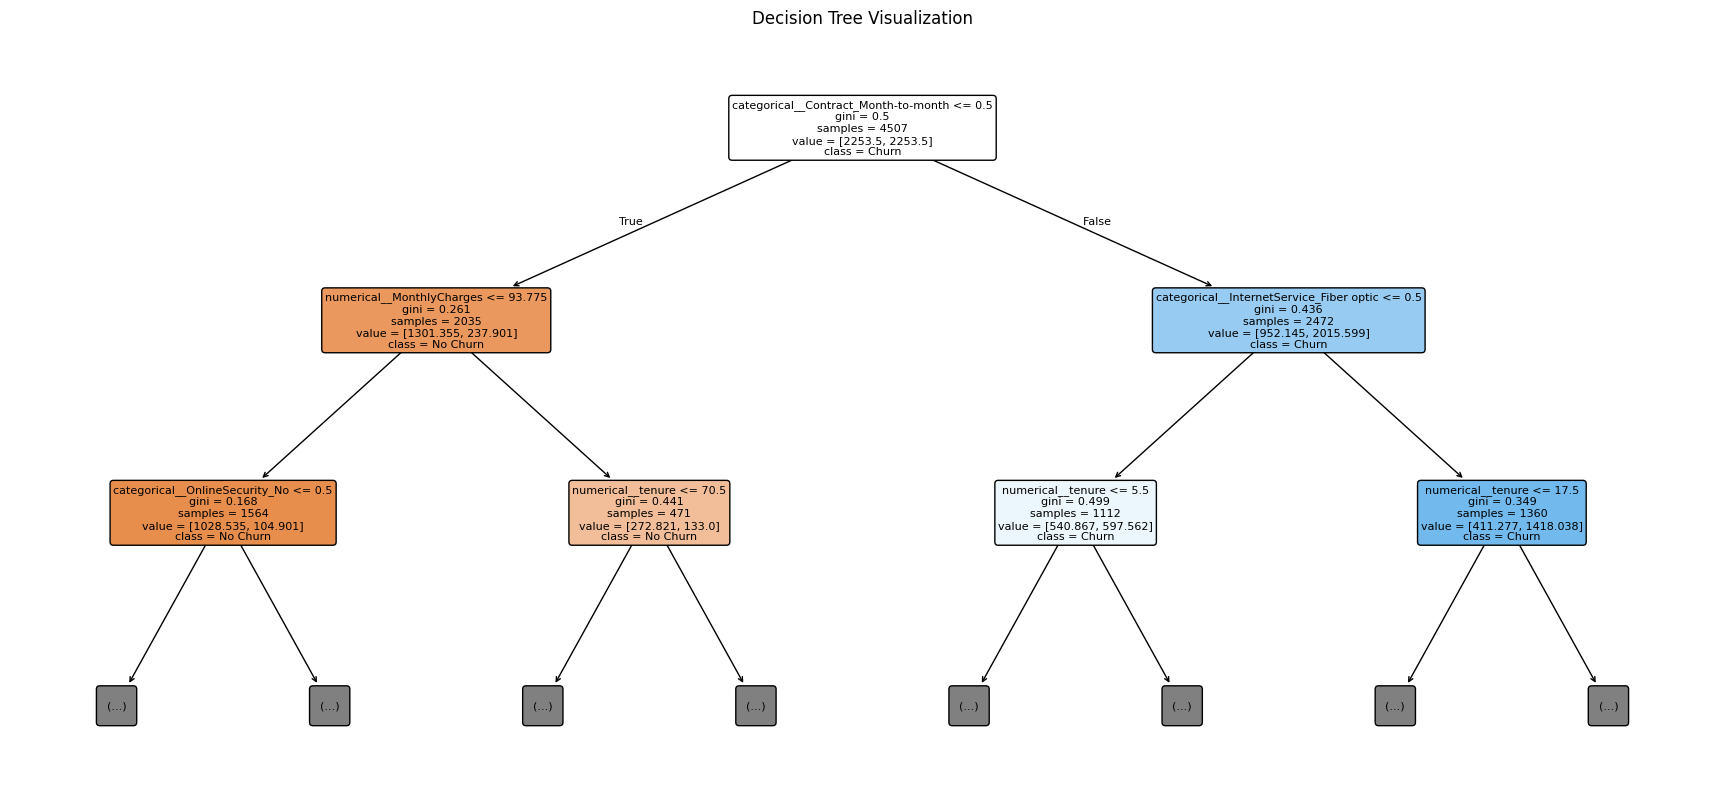

In [187]:
from sklearn.tree import plot_tree

tree = decision_tree_model.named_steps["classifier"]

feature_names = decision_tree_model.named_steps[
    "preprocessor"
].get_feature_names_out()

plt.figure(figsize=(22, 10))

plot_tree(
    tree,
    feature_names=feature_names,
    class_names=["No Churn", "Churn"],
    filled=True,
    rounded=True,
    max_depth=2,
    fontsize=8
)

plt.title("Decision Tree Visualization")
plt.show()

**Random Forest Classifier**

In [188]:
from sklearn.ensemble import RandomForestClassifier

In [189]:
random_forest_model = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])
random_forest_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges', 'CLV']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod',
                                                   'Tenure_Contract'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, random_state=42))])

In [190]:
y_prob_rf = random_forest_model.predict_proba(X_val)[:, 1]

print(y_prob_rf[:10])

[0.03       0.32375609 0.         0.325      0.         0.345
 0.025      0.82       0.         0.02      ]


**Model Evaluation**

In [191]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

In [192]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

In [193]:
results = []

for name, model in models.items():

    # Predictions
    y_pred = model.predict(X_val)

    # Churn probabilities
    y_prob = model.predict_proba(X_val)[:, 1]

    # Calculate metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1 Score": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7498,0.5213,0.7741,0.6230,0.8490
1,Decision Tree,0.7249,0.4847,0.4751,0.4799,0.6449
2,Random Forest,0.8021,0.6653,0.5216,0.5847,0.8403


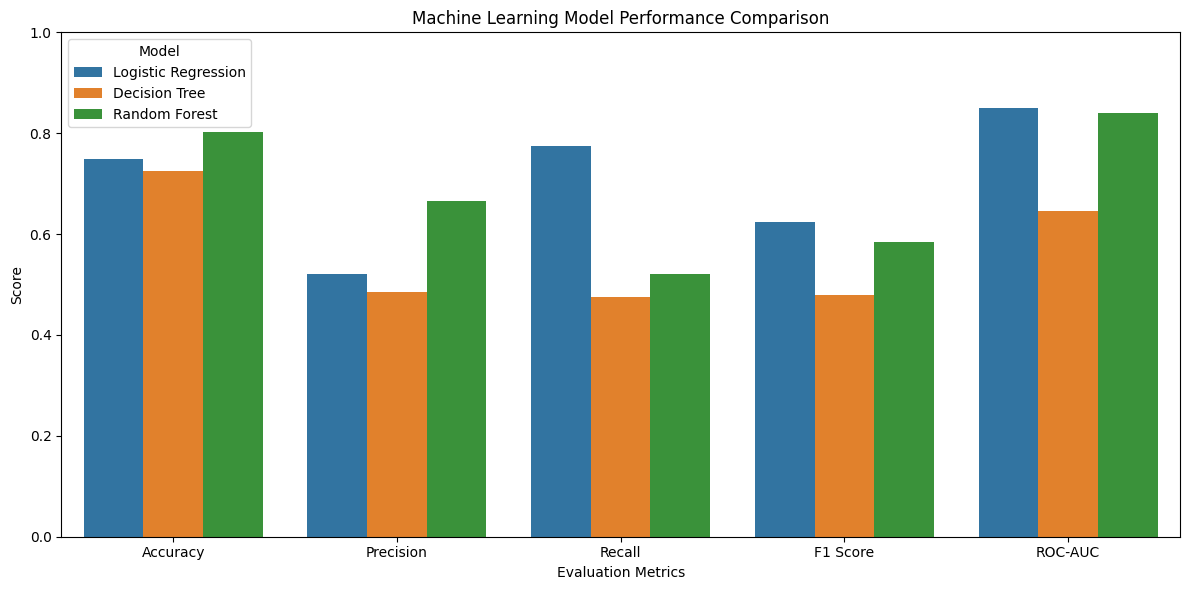

In [194]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

results_melted = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_melted,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [195]:
for name, model in models.items():

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    y_pred = model.predict(X_val)

    print(classification_report(
        y_val,
        y_pred,
        target_names=["No Churn", "Churn"]
    ))


Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.90      0.74      0.81       826
       Churn       0.52      0.77      0.62       301

    accuracy                           0.75      1127
   macro avg       0.71      0.76      0.72      1127
weighted avg       0.80      0.75      0.76      1127


Decision Tree
              precision    recall  f1-score   support

    No Churn       0.81      0.82      0.81       826
       Churn       0.48      0.48      0.48       301

    accuracy                           0.72      1127
   macro avg       0.65      0.65      0.65      1127
weighted avg       0.72      0.72      0.72      1127


Random Forest
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87       826
       Churn       0.67      0.52      0.58       301

    accuracy                           0.80      1127
   macro avg       0.75      0.71      0.73      1127
weighted avg       0.79

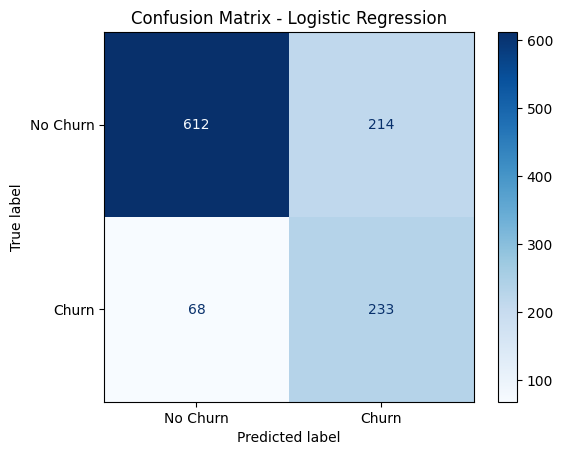

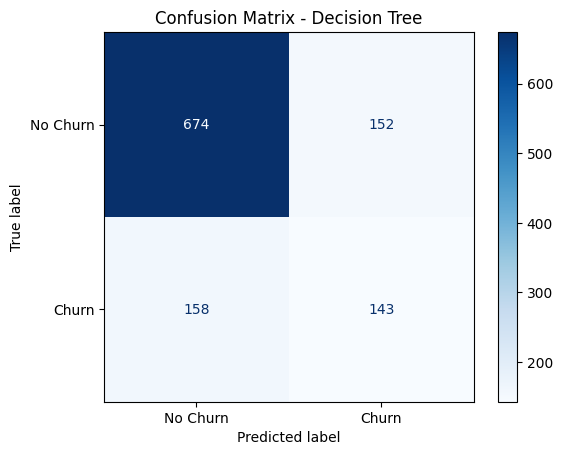

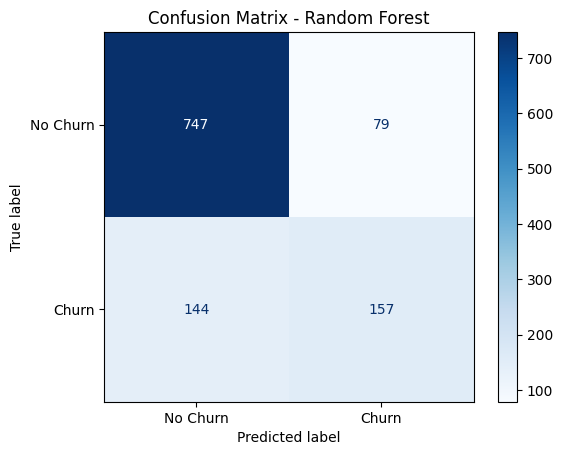

In [196]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for name, model in models.items():

    y_pred = model.predict(X_val)

    cm = confusion_matrix(y_val, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"]
    )

    disp.plot(cmap="Blues")

    plt.title(f"Confusion Matrix - {name}")
    plt.show()

**Evaluate and Compare the Three Models**

In [197]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

for name, model in models.items():

    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1 Score": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7498,0.5213,0.7741,0.6230,0.8490
1,Decision Tree,0.7249,0.4847,0.4751,0.4799,0.6449
2,Random Forest,0.8021,0.6653,0.5216,0.5847,0.8403


---
# Final model workflow (leakage-safe)

## Why this additional workflow is included
The earlier exploratory cleaning cells fill some missing values before the validation split. That is acceptable for demonstrating data cleaning, but it can leak information from the validation rows into preprocessing statistics. The workflow below reloads the untouched training and testing CSVs and places imputation, one-hot encoding and scaling inside scikit-learn pipelines. Consequently, these transformations are fitted only on the training data (and within each cross-validation fold during tuning). This section is the final source of model-comparison, tuning and test metrics.

In [198]:
# Set these paths to the locations of the two supplied CSV files.
# In Google Colab, mount Google Drive first and replace the paths if needed.
TRAIN_FILE_PATH = "Training_data(1).csv"
TEST_FILE_PATH = "Testing_data(1).csv"

train_raw = pd.read_csv("/content/drive/MyDrive/Data Science/Data Set/Training_data.csv")
test_raw = pd.read_csv("/content/drive/MyDrive/Data Science/Data Set/Testing_data.csv")

print("Training shape:", train_raw.shape)
print("Testing shape:", test_raw.shape)
print("Training columns match testing columns:", set(train_raw.columns) == set(test_raw.columns))
assert "Churn" in train_raw.columns and "Churn" in test_raw.columns, "Both supplied datasets must contain Churn for evaluation."
assert train_raw.columns.tolist() == test_raw.columns.tolist(), "Training and testing columns/order do not match."

Training shape: (5634, 21)
Testing shape: (1409, 21)
Training columns match testing columns: True


## Final preprocessing and feature engineering

`TotalCharges` is converted to numeric; blank strings become missing values. Rows with `tenure == 0` and missing `TotalCharges` are assigned zero because no tenure means no accumulated tenure-based charges in this dataset. Other missing numerical values are median-imputed and categorical values are mode-imputed inside the model pipeline. The two engineered features from this case study are retained: `CLV = tenure × MonthlyCharges` and the `Tenure_Contract` interaction. `customerID` is excluded.

In [199]:
def prepare_features(data):
    data = data.copy()
    data["TotalCharges"] = pd.to_numeric(
        data["TotalCharges"].astype("string").str.strip().replace("", pd.NA),
        errors="coerce"
    )
    if "tenure" in data.columns and "TotalCharges" in data.columns:
        data.loc[(data["tenure"] == 0) & data["TotalCharges"].isna(), "TotalCharges"] = 0

    # Numeric feature engineering; missing MonthlyCharges will be imputed by the pipeline.
    data["CLV"] = data["tenure"] * data["MonthlyCharges"]
    tenure_group = pd.cut(
        data["tenure"], bins=[-1, 12, 24, 48, 72],
        labels=["New", "Short_Term", "Medium_Term", "Long_Term"]
    ).astype("object")
    data["Tenure_Contract"] = tenure_group + "_" + data["Contract"].astype("string")
    return data

train_model_data = prepare_features(train_raw)
test_model_data = prepare_features(test_raw)

X_full = train_model_data.drop(columns=["customerID", "Churn"])
y_full = train_model_data["Churn"].map({"No": 0, "Yes": 1})
X_test_final = test_model_data.drop(columns=["customerID", "Churn"])
y_test_final = test_model_data["Churn"].map({"No": 0, "Yes": 1})

assert y_full.notna().all() and y_test_final.notna().all(), "Unexpected target labels found."
assert X_full.columns.tolist() == X_test_final.columns.tolist(), "Feature columns differ between train and test."

numeric_features = X_full.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_full.select_dtypes(include=["object", "category", "string"]).columns.tolist()
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Training missing values before pipeline:\n", X_full.isna().sum()[X_full.isna().sum() > 0])

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'CLV']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Tenure_Contract']
Training missing values before pipeline:
 gender            169
OnlineSecurity    169
MonthlyCharges    394
TotalCharges      281
CLV               394
dtype: int64


## Train/validation split and preprocessing pipelines

The supplied testing dataset is held back until the final evaluation. An 80/20 stratified split of the supplied training dataset is used to compare models and tune hyperparameters. Stratification preserves the churn/non-churn proportions in both partitions.

In [200]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

X_train_final, X_val_final, y_train_final, y_val_final = train_test_split(
    X_full, y_full, test_size=0.20, random_state=42, stratify=y_full
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor_final = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Training split:", X_train_final.shape)
print("Validation split:", X_val_final.shape)

Training split: (4507, 21)
Validation split: (1127, 21)


## Model development: three classifiers

The three required algorithms are Logistic Regression, Decision Tree and Random Forest. Logistic Regression uses scaling; tree-based models do not require scaling, but the common preprocessing pipeline is retained for a consistent and leakage-safe workflow. Class weighting is used to account for the lower proportion of churners.

In [201]:
models_final = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor_final),
        ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
    ]),
    "Decision Tree": Pipeline(steps=[
        ("preprocessor", preprocessor_final),
        ("classifier", DecisionTreeClassifier(class_weight="balanced", random_state=42))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor_final),
        ("classifier", RandomForestClassifier(
            n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1
        ))
    ])
}

for model in models_final.values():
    model.fit(X_train_final, y_train_final)

print("All three classifiers have been trained.")

All three classifiers have been trained.


## Model evaluation and comparison

Accuracy alone can be misleading because the classes are imbalanced. Recall measures the proportion of actual churners identified; precision measures how many predicted churners actually churn; F1 balances precision and recall; ROC-AUC measures ranking/discrimination across classification thresholds. For retention targeting, recall and F1 are particularly relevant, while precision matters because retention offers have a cost.

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7516,0.5232,0.7874,0.6286,0.8488
1,Random Forest,0.8066,0.6797,0.5216,0.5902,0.8351
2,Decision Tree,0.7400,0.5128,0.5316,0.5220,0.6732


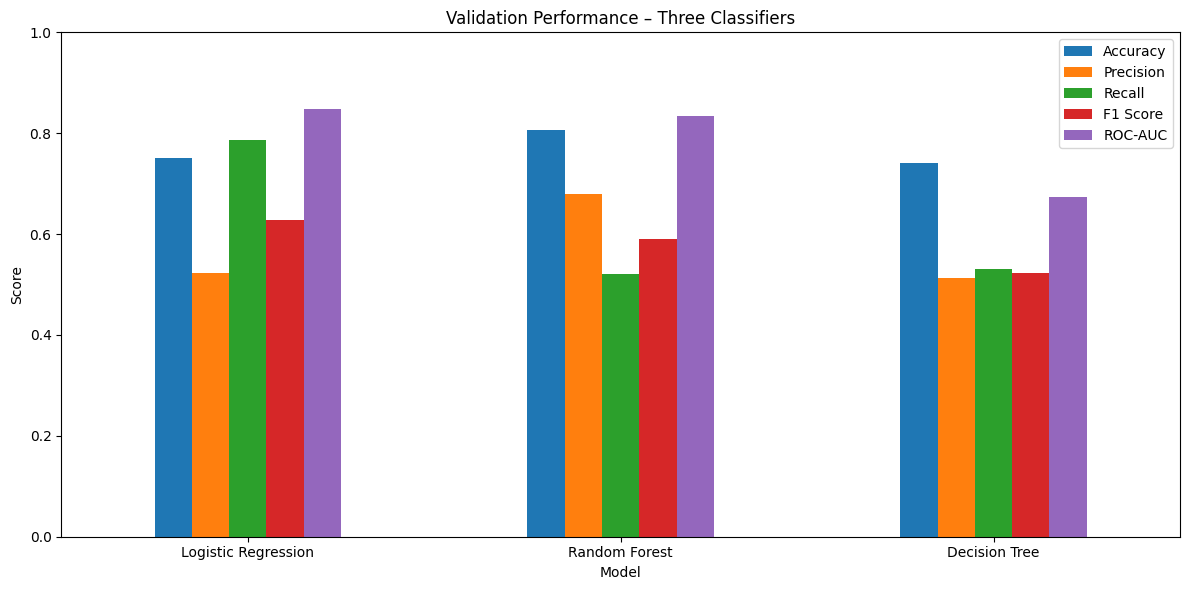

In [202]:
def evaluate_classifiers(models, X_eval, y_eval):
    rows = []
    for name, model in models.items():
        pred = model.predict(X_eval)
        prob = model.predict_proba(X_eval)[:, 1]
        rows.append({
            "Model": name,
            "Accuracy": accuracy_score(y_eval, pred),
            "Precision": precision_score(y_eval, pred, zero_division=0),
            "Recall": recall_score(y_eval, pred, zero_division=0),
            "F1 Score": f1_score(y_eval, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_eval, prob)
        })
    return pd.DataFrame(rows).sort_values("F1 Score", ascending=False).reset_index(drop=True)

final_results = evaluate_classifiers(models_final, X_val_final, y_val_final)
display(final_results.round(4))

ax = final_results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1), rot=0
)
ax.set_title("Validation Performance – Three Classifiers")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()


Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.91      0.74      0.81       826
       Churn       0.52      0.79      0.63       301

    accuracy                           0.75      1127
   macro avg       0.71      0.76      0.72      1127
weighted avg       0.80      0.75      0.76      1127



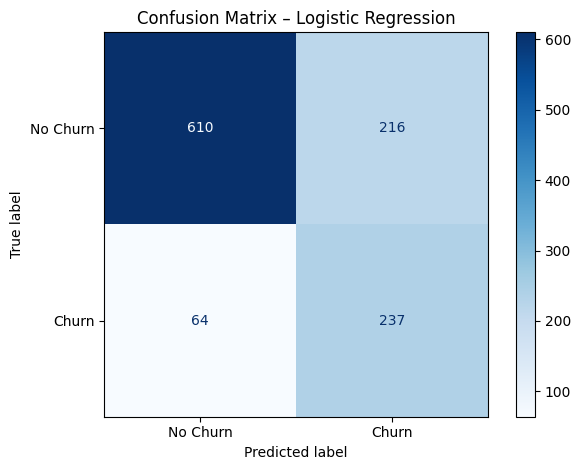


Decision Tree
              precision    recall  f1-score   support

    No Churn       0.83      0.82      0.82       826
       Churn       0.51      0.53      0.52       301

    accuracy                           0.74      1127
   macro avg       0.67      0.67      0.67      1127
weighted avg       0.74      0.74      0.74      1127



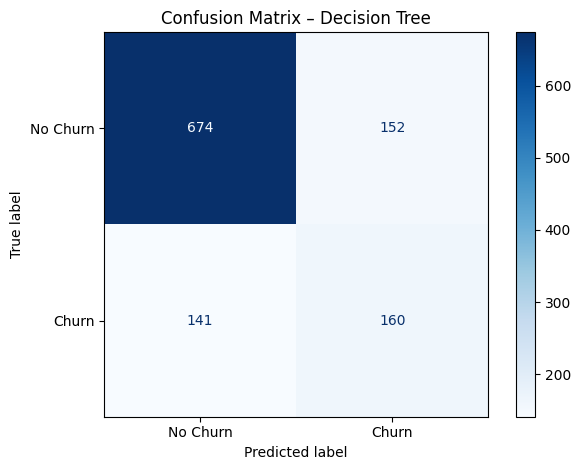


Random Forest
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87       826
       Churn       0.68      0.52      0.59       301

    accuracy                           0.81      1127
   macro avg       0.76      0.72      0.73      1127
weighted avg       0.80      0.81      0.80      1127



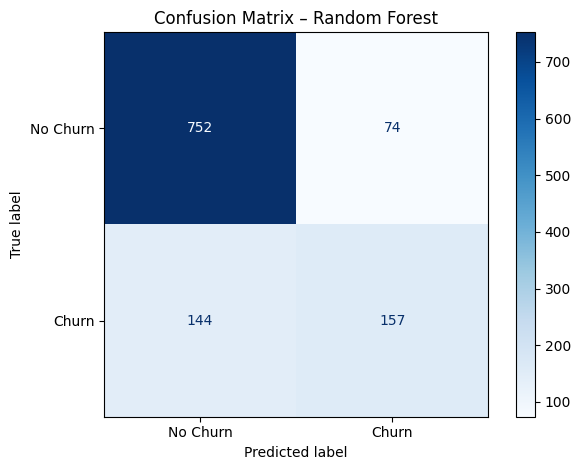

In [203]:
for name, model in models_final.items():
    print("\n", "=" * 55, "\n", name, "\n", "=" * 55, sep="")
    predictions = model.predict(X_val_final)
    print(classification_report(
        y_val_final, predictions, labels=[0, 1],
        target_names=["No Churn", "Churn"], zero_division=0
    ))
    ConfusionMatrixDisplay.from_predictions(
        y_val_final, predictions, display_labels=["No Churn", "Churn"], cmap="Blues"
    )
    plt.title(f"Confusion Matrix – {name}")
    plt.tight_layout()
    plt.show()

### Best baseline model selection

Select the baseline model using the validation results, giving priority to F1-score and ROC-AUC while checking churn recall and precision. Do not select a model from accuracy alone. The code below selects the highest-F1 model automatically for reference; review the full table before confirming the business trade-off.

In [204]:
best_baseline_name = final_results.iloc[0]["Model"]
print("Highest validation F1-score:", best_baseline_name)
print("Validation metrics:")
display(final_results.iloc[[0]].round(4))

Highest validation F1-score: Logistic Regression
Validation metrics:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7516,0.5232,0.7874,0.6286,0.8488


## Hyperparameter tuning with GridSearchCV

The Logistic Regression model is tuned because the earlier validation comparison identified it as the strongest model for churn recall/F1 in this notebook. GridSearchCV uses five-fold stratified cross-validation on the training partition only. The validation partition remains untouched during the search. `C` controls regularization strength; `class_weight` controls the relative penalty for errors in each class; `solver` specifies the optimization algorithm. The search uses F1 as the selection metric to balance precision and recall for the churn class.

In [205]:
# Tune Logistic Regression using the same preprocessing pipeline.
logistic_pipeline_final = models_final["Logistic Regression"]
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": ["balanced", None],
    "classifier__solver": ["liblinear", "lbfgs"]
}

grid_search_final = GridSearchCV(
    estimator=logistic_pipeline_final,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)
grid_search_final.fit(X_train_final, y_train_final)

print("Best parameters:", grid_search_final.best_params_)
print("Best mean CV F1-score:", round(grid_search_final.best_score_, 4))
tuned_logistic = grid_search_final.best_estimator_

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters: {'classifier__C': 0.01, 'classifier__class_weight': 'balanced', 'classifier__solver': 'liblinear'}
Best mean CV F1-score: 0.6356


### Evaluate tuned model and compare with the baseline

The tuned model is evaluated on the same validation partition used for baseline comparison. Tuning does not guarantee improvement; report the measured values and choose based on the actual trade-off.

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned Logistic Regression,0.7631,0.5385,0.7907,0.6406,0.8469
1,Original Logistic Regression,0.7516,0.5232,0.7874,0.6286,0.8488


Tuned Logistic Regression classification report:
              precision    recall  f1-score   support

    No Churn       0.91      0.75      0.82       826
       Churn       0.54      0.79      0.64       301

    accuracy                           0.76      1127
   macro avg       0.72      0.77      0.73      1127
weighted avg       0.81      0.76      0.77      1127



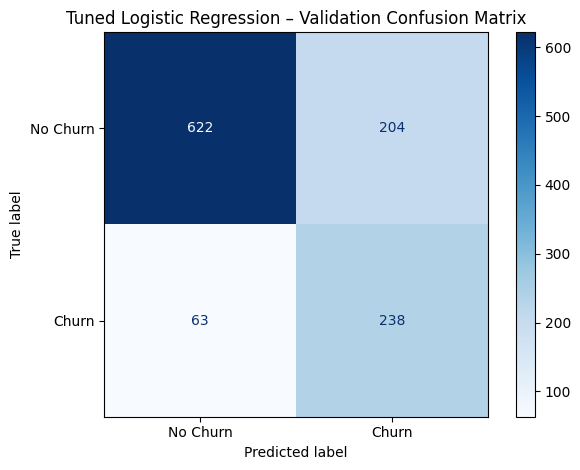

In [206]:
baseline_logistic = models_final["Logistic Regression"]
comparison_models = {
    "Original Logistic Regression": baseline_logistic,
    "Tuned Logistic Regression": tuned_logistic
}
tuned_comparison = evaluate_classifiers(comparison_models, X_val_final, y_val_final)
display(tuned_comparison.round(4))

print("Tuned Logistic Regression classification report:")
y_val_tuned = tuned_logistic.predict(X_val_final)
print(classification_report(
    y_val_final, y_val_tuned, labels=[0, 1],
    target_names=["No Churn", "Churn"], zero_division=0
))
ConfusionMatrixDisplay.from_predictions(
    y_val_final, y_val_tuned, display_labels=["No Churn", "Churn"], cmap="Blues"
)
plt.title("Tuned Logistic Regression – Validation Confusion Matrix")
plt.tight_layout()
plt.show()

## Final evaluation on the separate testing dataset

After model selection and tuning, evaluate the tuned Logistic Regression on the separate testing CSV. This dataset was not used for model fitting, cross-validation or hyperparameter selection. It is therefore the final estimate of performance on unseen records. Do not use these test results to tune the model again.

Final test metrics:


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,0.7388,0.4973,0.7671,0.6034,0.8339


Final test classification report:
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1044
       Churn       0.50      0.77      0.60       365

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.74      0.75      1409



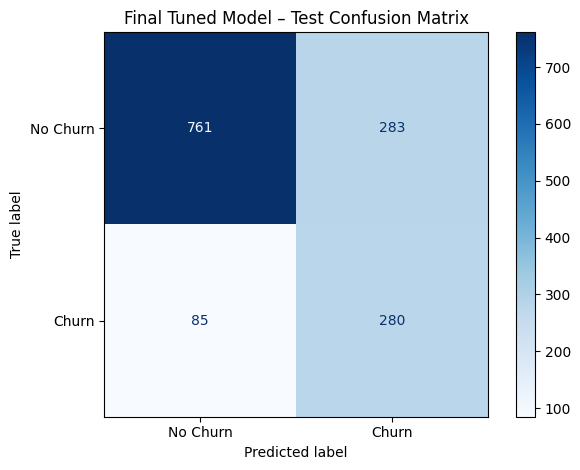

In [207]:
# Fit the selected model on the complete supplied training dataset, then test once.
# Refit uses the full labelled training set after hyperparameters were selected on its 80% split.
final_model = tuned_logistic
final_model.fit(X_full, y_full)

y_test_pred = final_model.predict(X_test_final)
y_test_prob = final_model.predict_proba(X_test_final)[:, 1]

final_test_metrics = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test_final, y_test_pred),
    "Precision": precision_score(y_test_final, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test_final, y_test_pred, zero_division=0),
    "F1 Score": f1_score(y_test_final, y_test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_final, y_test_prob)
}])
print("Final test metrics:")
display(final_test_metrics.round(4))
print("Final test classification report:")
print(classification_report(
    y_test_final, y_test_pred, labels=[0, 1],
    target_names=["No Churn", "Churn"], zero_division=0
))
ConfusionMatrixDisplay.from_predictions(
    y_test_final, y_test_pred, display_labels=["No Churn", "Churn"], cmap="Blues"
)
plt.title("Final Tuned Model – Test Confusion Matrix")
plt.tight_layout()
plt.show()

### Verified results from the final workflow

The final workflow was executed against the supplied `Training_data(1).csv` and `Testing_data(1).csv` files. The measured results were:

**Validation comparison (before tuning):**

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.7516 | 0.5232 | **0.7874** | **0.6286** | **0.8488** |
| Decision Tree | 0.7400 | 0.5128 | 0.5316 | 0.5220 | 0.6732 |
| Random Forest | **0.8066** | **0.6797** | 0.5216 | 0.5902 | 0.8351 |

Logistic Regression is selected for tuning because it has the highest churn recall, F1-score and ROC-AUC. Random Forest has the highest accuracy and precision, but identifies substantially fewer actual churners. The preferred model therefore depends on the business cost of missed churners versus unnecessary retention offers.

**GridSearchCV:** Best parameters were `C=0.01`, `class_weight='balanced'`, and `solver='liblinear'`. The best mean five-fold cross-validation F1-score was **0.6356**. On the validation split, tuning increased F1-score from **0.6286 to 0.6406** and recall from **0.7874 to 0.7907**; ROC-AUC changed slightly from **0.8488 to 0.8469**. This is a modest improvement, not an improvement in every metric.

**Separate testing dataset – tuned Logistic Regression:** Accuracy **0.7388**, precision **0.4973**, recall **0.7671**, F1-score **0.6034**, ROC-AUC **0.8339**. Test performance is lower than validation F1, but ROC-AUC remains reasonably close. The model identifies about 77% of actual churners, while precision indicates that about half of its churn alerts are true churners.

These values are recorded from one execution of the included workflow. Re-run the notebook in your environment; results should match if the CSV files and software versions are the same.

Conclusion


This project developed three machine-learning models to predict customer churn: Logistic Regression, Decision Tree and Random Forest. After comparing their performance, Logistic Regression was selected because it achieved the highest recall (78.74%), F1-score (62.86%) and ROC-AUC (84.88%).

GridSearchCV improved the validation F1-score from 62.86% to 64.06%. The tuned model achieved the following results on the separate testing dataset:
- Accuracy: 73.88%
- Precision: 49.73%
- Recall: 76.71%
- F1-score: 60.34%
- ROC-AUC: 83.39%


The results show that the model can identify a substantial proportion of customers likely to churn, although some predictions are incorrect.


Business Recommendations
- Prioritize high-risk customers for retention campaigns.
- Offer personalized incentives based on customer behaviour and service usage.
- Monitor false predictions to reduce unnecessary retention costs.
- Regularly evaluate and retrain the model using updated customer data.